In [1]:
from pathlib import Path
import random
import numpy as np
import torch

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Robust local path discovery (works outside Kaggle)
NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR = NOTEBOOK_DIR
if not (PROJECT_DIR / "data").exists() and (PROJECT_DIR / "archive_theia" / "data").exists():
    PROJECT_DIR = PROJECT_DIR / "archive_theia"

DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "head_ct"
LABELS_PATH = DATA_DIR / "labels.csv"
WORK_DIR = PROJECT_DIR / "working"
WORK_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project dir: {PROJECT_DIR}")
print(f"Image dir exists: {IMAGE_DIR.exists()} ({IMAGE_DIR})")
print(f"Labels path exists: {LABELS_PATH.exists()} ({LABELS_PATH})")
print(f"Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")

Project dir: /home3/rudrapra001/FYP-Research/archive_theia
Image dir exists: True (/home3/rudrapra001/FYP-Research/archive_theia/data/head_ct)
Labels path exists: True (/home3/rudrapra001/FYP-Research/archive_theia/data/labels.csv)
Device: cuda


# Import libraries

In [29]:
import os
from os import listdir
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.models as models

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
 )

from PIL import Image

import warnings
warnings.filterwarnings("ignore")

# Reading data

In [3]:
labels = pd.read_csv(LABELS_PATH)
labels.head()

,id,hemorrhage
0,0,1
1,1,1
2,2,1
3,3,1
4,4,1


In [4]:
labels.columns = [c.strip() for c in labels.columns]
if "hemorrhage" not in labels.columns:
    raise ValueError(f"Expected 'hemorrhage' column, found: {labels.columns.tolist()}")

# Ensure image ids match local filenames like 000.png
labels["id"] = labels["id"].astype(int).apply(lambda x: f"{x:03d}.png")
labels["hemorrhage"] = labels["hemorrhage"].astype(int)

# Keep only rows with existing files
labels = labels[labels["id"].apply(lambda name: (IMAGE_DIR / name).exists())].reset_index(drop=True)
labels["hemorrhage"].value_counts()

hemorrhage
1    100
0    100
Name: count, dtype: int64

In [6]:
# IDs are already normalized in the previous cell
labels.head()

,id,hemorrhage
0,000.png,1
1,001.png,1
2,002.png,1
3,003.png,1
4,004.png,1


In [7]:
classes=list(labels['hemorrhage'].unique())
classes

[1, 0]

# Data Augmentation

In [8]:
AUGMENT_DIR = WORK_DIR / "data-augmentation"
AUGMENT_DIR.mkdir(parents=True, exist_ok=True)
AUGMENT_DIR

PosixPath('/home3/rudrapra001/FYP-Research/archive_theia/working/data-augmentation')

In [9]:
# Offline augmentation is optional; we will use online augmentation in transforms.
# Keeping this cell as a placeholder for compatibility with the original notebook.
def apply_augmentation(image):
    return image

In [10]:
# No file-copy augmentation needed when using online transforms.
print(f"Using original images directly from: {IMAGE_DIR}")
print(f"Total source images: {len(list(IMAGE_DIR.glob('*.png')))}")

Using original images directly from: /home3/rudrapra001/FYP-Research/archive_theia/data/head_ct
Total source images: 200


In [11]:
# Use original labels directly (no expanded csv generation).
expanded_labels = labels.copy()
expanded_labels.to_csv(WORK_DIR / "prepared_labels.csv", index=False)
expanded_labels.head()

,id,hemorrhage
0,000.png,1
1,001.png,1
2,002.png,1
3,003.png,1
4,004.png,1


In [12]:
expanded_labels.tail(10)

,id,hemorrhage
190,190.png,0
191,191.png,0
192,192.png,0
193,193.png,0
194,194.png,0
195,195.png,0
196,196.png,0
197,197.png,0
198,198.png,0
199,199.png,0


# Spliting dataset into train and test datasets

In [13]:
train_label_df, test_label_df = train_test_split(
    expanded_labels,
    test_size=0.15,
    shuffle=True,
    random_state=SEED,
    stratify=expanded_labels["hemorrhage"]
)

train_label_df = train_label_df.reset_index(drop=True)
test_label_df = test_label_df.reset_index(drop=True)

train_label_df.to_csv(WORK_DIR / "train_csv.csv", index=False)
test_label_df.to_csv(WORK_DIR / "test_csv.csv", index=False)

print(f"Train size: {len(train_label_df)} | Test size: {len(test_label_df)}")
print("Train class distribution:")
print(train_label_df["hemorrhage"].value_counts(normalize=True))

Train size: 170 | Test size: 30
Train class distribution:
hemorrhage
1    0.5
0    0.5
Name: proportion, dtype: float64


# Dataloading

In [14]:
class CTDataset(Dataset):
    def __init__(self, root_dir, annotations, transform=None):
        self.root_dir = str(root_dir)
        if isinstance(annotations, pd.DataFrame):
            self.annotations = annotations.reset_index(drop=True).copy()
        else:
            self.annotations = pd.read_csv(annotations).reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, index):
        img_id = self.annotations.iloc[index]["id"]
        img_path = os.path.join(self.root_dir, img_id)
        img = Image.open(img_path).convert("L")
        y_label = torch.tensor(int(self.annotations.iloc[index]["hemorrhage"]), dtype=torch.long)

        if self.transform is not None:
            img = self.transform(img)

        return img, y_label

In [15]:
# Input pipeline
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [16]:
batch_size = 16
num_workers = 2

trainset = CTDataset(
    root_dir=IMAGE_DIR,
    annotations=train_label_df,
    transform=train_transform
)

testset = CTDataset(
    root_dir=IMAGE_DIR,
    annotations=test_label_df,
    transform=eval_transform
)

trainloader = DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available()
 )

testloader = DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available()
 )

len(trainset), len(testset)

(170, 30)

# Data Visualization

In [17]:
images, labels = next(iter(trainloader))

In [18]:
labels[0]

tensor(1)

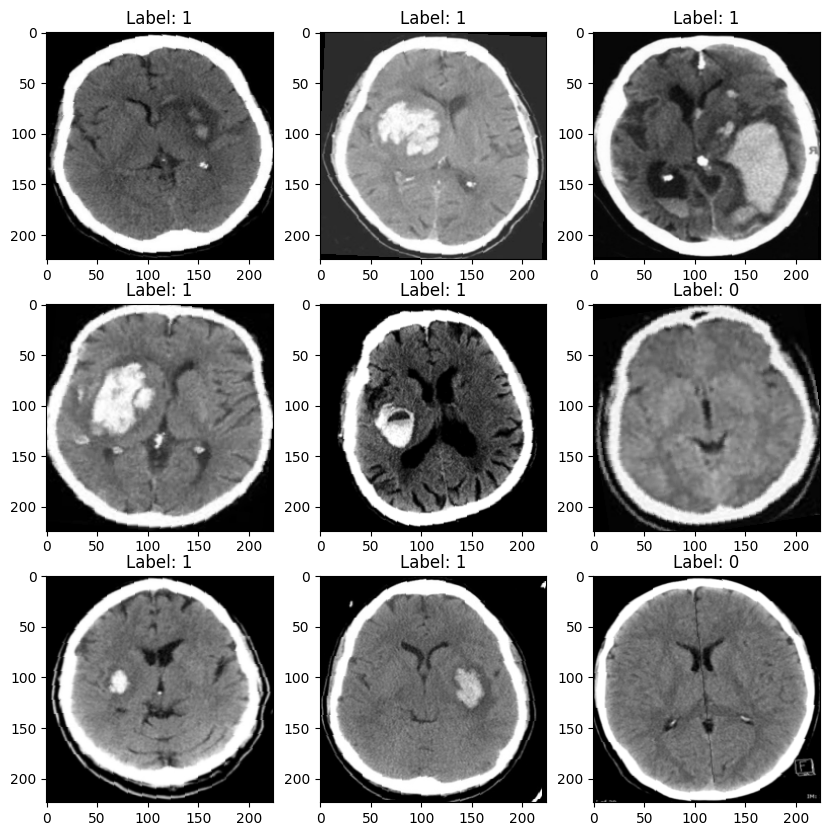

In [19]:
plt.figure(figsize=(10, 10))
for i in range(0,9):
    plt.subplot(331 + i)
    plt.imshow(images[i][0], cmap="gray")
    plt.title("\nLabel: 0" if labels[i] == 0 else "Label: 1")

# Building the model

In [25]:
class CTResNetBinary(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        try:
            backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        except Exception:
            backbone = models.resnet18(pretrained=True)

        # Adapt first layer for 1-channel CT input
        old_conv = backbone.conv1
        backbone.conv1 = nn.Conv2d(
            1, old_conv.out_channels, kernel_size=old_conv.kernel_size,
            stride=old_conv.stride, padding=old_conv.padding, bias=False
        )
        with torch.no_grad():
            backbone.conv1.weight[:] = old_conv.weight.mean(dim=1, keepdim=True)

        in_features = backbone.fc.in_features
        backbone.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, 2)
        )

        self.model = backbone

    def forward(self, x):
        return self.model(x)

# Model training

In [26]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Training configuration
num_folds = 5
max_epochs = 12
early_stopping_patience = 3
learning_rate = 2e-4
weight_decay = 1e-4
batch_size = 16
num_workers = 2

print(f"Using device: {device}")
print(f"CV setup: {num_folds} folds, {max_epochs} max epochs, patience={early_stopping_patience}")

Using device: cuda
CV setup: 5 folds, 12 max epochs, patience=3


In [27]:
# 5-fold stratified cross-validation with early stopping
skf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=SEED)

oof_probs = np.zeros(len(expanded_labels), dtype=np.float32)
oof_preds = np.zeros(len(expanded_labels), dtype=np.int64)
fold_metrics = []

for fold, (train_idx, val_idx) in enumerate(
    skf.split(expanded_labels["id"].values, expanded_labels["hemorrhage"].values), start=1
):
    print(f"\n{'='*30} Fold {fold}/{num_folds} {'='*30}")
    
    fold_train_df = expanded_labels.iloc[train_idx].reset_index(drop=True)
    fold_val_df = expanded_labels.iloc[val_idx].reset_index(drop=True)

    trainset = CTDataset(root_dir=IMAGE_DIR, annotations=fold_train_df, transform=train_transform)
    valset = CTDataset(root_dir=IMAGE_DIR, annotations=fold_val_df, transform=eval_transform)

    trainloader = DataLoader(
        trainset, batch_size=batch_size, shuffle=True,
        num_workers=num_workers, pin_memory=torch.cuda.is_available()
    )
    valloader = DataLoader(
        valset, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=torch.cuda.is_available()
    )

    model = CTResNetBinary(dropout=0.3).to(device)

    class_counts = fold_train_df["hemorrhage"].value_counts().sort_index()
    class_weights = torch.tensor(
        [len(fold_train_df) / (2.0 * class_counts.get(i, 1)) for i in range(2)],
        dtype=torch.float32,
        device=device
    )
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=1)

    best_val_auc = -1.0
    best_state = None
    best_epoch = 0
    patience_counter = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_count = 0

        for images, labels in trainloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)
            preds = outputs.argmax(dim=1)
            train_correct += (preds == labels).sum().item()
            train_count += labels.size(0)

        model.eval()
        val_loss_sum = 0.0
        val_labels = []
        val_preds = []
        val_probs = []

        with torch.no_grad():
            for images, labels in valloader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)
                loss = criterion(outputs, labels)
                probs = torch.softmax(outputs, dim=1)[:, 1]
                preds = outputs.argmax(dim=1)

                val_loss_sum += loss.item() * labels.size(0)
                val_labels.extend(labels.cpu().numpy().tolist())
                val_preds.extend(preds.cpu().numpy().tolist())
                val_probs.extend(probs.cpu().numpy().tolist())

        train_loss = train_loss_sum / max(train_count, 1)
        val_loss = val_loss_sum / max(len(fold_val_df), 1)
        train_acc = train_correct / max(train_count, 1)
        val_acc = accuracy_score(val_labels, val_preds)
        val_f1 = f1_score(val_labels, val_preds, zero_division=0)
        val_auc = roc_auc_score(val_labels, val_probs)
        val_pr_auc = average_precision_score(val_labels, val_probs)

        scheduler.step(val_auc)

        print(
            f"Fold {fold} | Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f} | Val ROC-AUC: {val_auc:.4f} | Val PR-AUC: {val_pr_auc:.4f}"
        )

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= early_stopping_patience:
                print(f"Early stopping on fold {fold} at epoch {epoch}")
                break

    model.load_state_dict(best_state)
    model.eval()
    final_val_labels = []
    final_val_preds = []
    final_val_probs = []

    with torch.no_grad():
        for images, labels in valloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            preds = outputs.argmax(dim=1)

            final_val_labels.extend(labels.cpu().numpy().tolist())
            final_val_preds.extend(preds.cpu().numpy().tolist())
            final_val_probs.extend(probs.cpu().numpy().tolist())

    oof_probs[val_idx] = np.array(final_val_probs, dtype=np.float32)
    oof_preds[val_idx] = np.array(final_val_preds, dtype=np.int64)

    fold_result = {
        "fold": fold,
        "best_epoch": best_epoch,
        "val_acc": accuracy_score(final_val_labels, final_val_preds),
        "val_f1": f1_score(final_val_labels, final_val_preds, zero_division=0),
        "val_roc_auc": roc_auc_score(final_val_labels, final_val_probs),
        "val_pr_auc": average_precision_score(final_val_labels, final_val_probs)
    }
    fold_metrics.append(fold_result)
    
    torch.save(best_state, WORK_DIR / f"best_model_fold_{fold}.pt")
    print(f"Saved best fold-{fold} checkpoint to {WORK_DIR / f'best_model_fold_{fold}.pt'}")

results_df = pd.DataFrame(fold_metrics)
cv_summary = {
    "oof_acc": accuracy_score(expanded_labels["hemorrhage"].values, oof_preds),
    "oof_f1": f1_score(expanded_labels["hemorrhage"].values, oof_preds, zero_division=0),
    "oof_roc_auc": roc_auc_score(expanded_labels["hemorrhage"].values, oof_probs),
    "oof_pr_auc": average_precision_score(expanded_labels["hemorrhage"].values, oof_probs)
}

print("\nCross-validation fold metrics:")
display(results_df)
print("\nOOF summary metrics:")
print(cv_summary)


============================== Fold 1/5 ==============================


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home3/rudrapra001/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100.0%


Fold 1 | Epoch 01 | Train Loss: 0.6053 | Train Acc: 0.6625 | Val Loss: 0.2584 | Val Acc: 0.9000 | Val F1: 0.9000 | Val ROC-AUC: 0.9825 | Val PR-AUC: 0.9829
Fold 1 | Epoch 02 | Train Loss: 0.1538 | Train Acc: 0.9688 | Val Loss: 0.1673 | Val Acc: 0.9500 | Val F1: 0.9474 | Val ROC-AUC: 0.9975 | Val PR-AUC: 0.9976
Fold 1 | Epoch 03 | Train Loss: 0.0698 | Train Acc: 0.9812 | Val Loss: 0.3666 | Val Acc: 0.8750 | Val F1: 0.8571 | Val ROC-AUC: 0.9875 | Val PR-AUC: 0.9887
Fold 1 | Epoch 04 | Train Loss: 0.0231 | Train Acc: 0.9938 | Val Loss: 0.1862 | Val Acc: 0.9250 | Val F1: 0.9189 | Val ROC-AUC: 0.9975 | Val PR-AUC: 0.9976
Fold 1 | Epoch 05 | Train Loss: 0.0102 | Train Acc: 1.0000 | Val Loss: 0.1604 | Val Acc: 0.9500 | Val F1: 0.9474 | Val ROC-AUC: 0.9950 | Val PR-AUC: 0.9955
Early stopping on fold 1 at epoch 5
Saved best fold-1 checkpoint to /home3/rudrapra001/FYP-Research/archive_theia/working/best_model_fold_1.pt

============================== Fold 2/5 ==============================
Fold 

,fold,best_epoch,val_acc,val_f1,val_roc_auc,val_pr_auc
0,1,2,0.950,0.947368,0.9975,0.997619
1,2,6,0.925,0.918919,1.0000,1.000000
2,3,2,0.775,0.816327,0.9825,0.984848
3,4,5,0.950,0.947368,0.9925,0.993478
4,5,6,0.950,0.947368,1.0000,1.000000



OOF summary metrics:
{'oof_acc': 0.91, 'oof_f1': 0.91, 'oof_roc_auc': 0.9647000000000001, 'oof_pr_auc': 0.9644107478000312}


In [28]:
# Out-of-fold diagnostics
true_labels = expanded_labels["hemorrhage"].values

print("OOF Accuracy:", accuracy_score(true_labels, oof_preds))
print("OOF F1-score:", f1_score(true_labels, oof_preds, zero_division=0))
print("OOF ROC-AUC:", roc_auc_score(true_labels, oof_probs))
print("OOF PR-AUC:", average_precision_score(true_labels, oof_probs))
print("\nOOF Confusion matrix:\n", confusion_matrix(true_labels, oof_preds))
print("\nOOF Classification report:\n")
print(classification_report(true_labels, oof_preds, digits=4, zero_division=0))

results_df.describe(include='all')

OOF Accuracy: 0.91
OOF F1-score: 0.91
OOF ROC-AUC: 0.9647000000000001
OOF PR-AUC: 0.9644107478000312

OOF Confusion matrix:
 [[91  9]
 [ 9 91]]

OOF Classification report:

              precision    recall  f1-score   support

           0     0.9100    0.9100    0.9100       100
           1     0.9100    0.9100    0.9100       100

    accuracy                         0.9100       200
   macro avg     0.9100    0.9100    0.9100       200
weighted avg     0.9100    0.9100    0.9100       200



,fold,best_epoch,val_acc,val_f1,val_roc_auc,val_pr_auc
count,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000
mean,3.000000,4.20000,0.91000,0.915470,0.994500,0.995189
std,1.581139,2.04939,0.07624,0.056776,0.007374,0.006365
min,1.000000,2.00000,0.77500,0.816327,0.982500,0.984848
25%,2.000000,2.00000,0.92500,0.918919,0.992500,0.993478
50%,3.000000,5.00000,0.95000,0.947368,0.997500,0.997619
75%,4.000000,6.00000,0.95000,0.947368,1.000000,1.000000
max,5.000000,6.00000,0.95000,0.947368,1.000000,1.000000


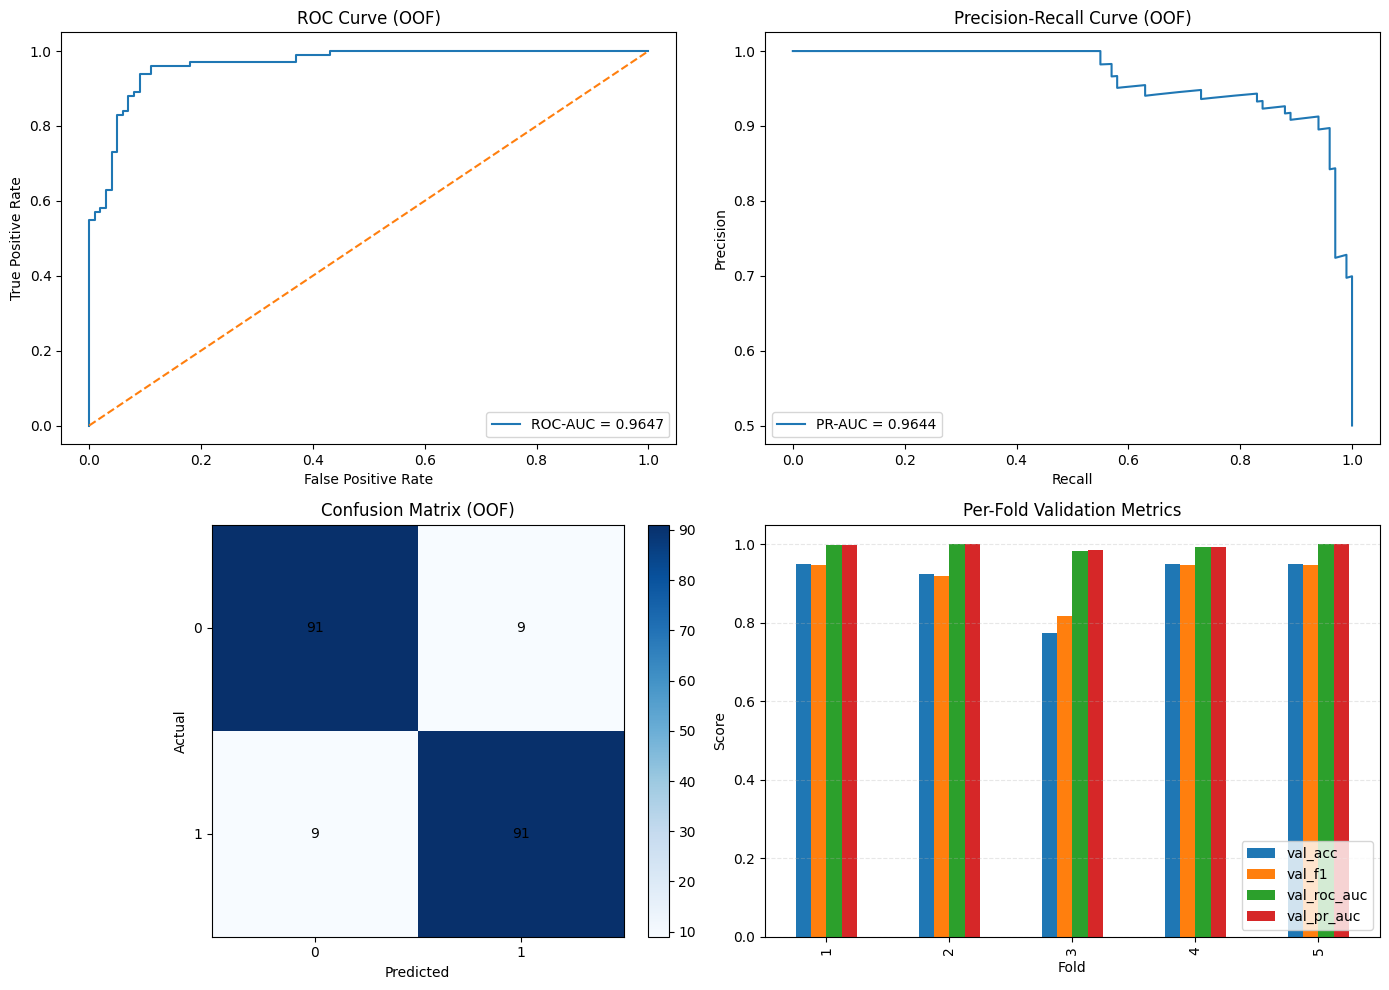

In [30]:
# Visual diagnostics: ROC curve, PR curve, confusion matrix, and fold metrics
true_labels = expanded_labels["hemorrhage"].values
fpr, tpr, _ = roc_curve(true_labels, oof_probs)
precision, recall, _ = precision_recall_curve(true_labels, oof_probs)
cm = confusion_matrix(true_labels, oof_preds)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ROC
axes[0, 0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(true_labels, oof_probs):.4f}")
axes[0, 0].plot([0, 1], [0, 1], linestyle="--")
axes[0, 0].set_title("ROC Curve (OOF)")
axes[0, 0].set_xlabel("False Positive Rate")
axes[0, 0].set_ylabel("True Positive Rate")
axes[0, 0].legend(loc="lower right")

# Precision-Recall
axes[0, 1].plot(recall, precision, label=f"PR-AUC = {average_precision_score(true_labels, oof_probs):.4f}")
axes[0, 1].set_title("Precision-Recall Curve (OOF)")
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].legend(loc="lower left")

# Confusion matrix heatmap-style plot (matplotlib only)
im = axes[1, 0].imshow(cm, cmap="Blues")
axes[1, 0].set_title("Confusion Matrix (OOF)")
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("Actual")
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_yticks([0, 1])
for r in range(cm.shape[0]):
    for c in range(cm.shape[1]):
        axes[1, 0].text(c, r, cm[r, c], ha="center", va="center")
fig.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

# Fold metrics
plot_df = results_df.set_index("fold")[["val_acc", "val_f1", "val_roc_auc", "val_pr_auc"]]
plot_df.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Per-Fold Validation Metrics")
axes[1, 1].set_xlabel("Fold")
axes[1, 1].set_ylabel("Score")
axes[1, 1].set_ylim(0.0, 1.05)
axes[1, 1].grid(axis="y", linestyle="--", alpha=0.3)
axes[1, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()